# Insper - Modelagem e Simulação do Mundo Físico

## Projeto 2 - Termodinâmica | Grupo 10

**Integrantes:** Antonio Dias, Marcos Rodrigues e Pedro Toscano

### Como este notebook está organizado

| Seção | O que tem | Pergunta que ela responde |
|---|---|---|
| 1. Definição do modelo | sistema, pergunta e hipóteses | O que estamos estudando e o que simplificamos? |
| 2. Modelagem | esquema, diagrama, equações e parâmetros | Como o calor entra e sai da panela e da água? |
| 3. Implementação | função do modelo e gráficos | Como as temperaturas mudam com o tempo? |
| 4. Validação | modelo × experimento | O modelo representa a realidade? |
| 5. Gráfico conclusivo | tempo até ferver × potência | Qual é a resposta da nossa pergunta? |
| 6. Resumo para a apresentação | números principais e perguntas prováveis | O que falar e como responder? |

**A ideia do projeto em uma frase:** o fogão coloca energia na panela; a panela passa parte dessa energia para a água e perde outra parte para o ar; a água também perde energia para o ar. A temperatura de cada um sobe enquanto entra mais energia do que sai.

As caixas **"Para entender"** explicam a ideia por trás de cada passo, com exemplos do dia a dia.

---
## 1. Definição do modelo

**Sistema:** uma panela de aço inox com $1,123\ kg$ de água (cerca de $1,1\ L$), **sem tampa**, em cima de um fogão de **indução**.

**Pergunta:** quanto tempo a água demora para ferver em função da potência do fogão?

> **Para entender: como o fogão de indução esquenta?** Embaixo do vidro do fogão há uma bobina (um fio enrolado) com corrente alternada. Ela cria um campo magnético que troca de sentido muitas vezes por segundo, e esse campo induz correntes elétricas no **fundo de aço da panela**. Essas correntes esquentam o aço (efeito Joule, o mesmo do chuveiro elétrico). Ou seja: o fogão não esquenta a água diretamente. Ele esquenta a **panela**, e a panela esquenta a água. Por isso o modelo trata a panela e a água separadamente.

**Hipóteses** (as simplificações que fizemos):

| # | Hipótese | Por que faz sentido |
|---|---|---|
| 1 | A panela é um cilindro de aço de raio $r$, altura $H$ e parede fina de espessura $d$ | é o formato real da panela; o cabo foi desprezado |
| 2 | A panela e a água têm, cada uma, **uma só temperatura** em cada instante ($T_p$ e $T_a$) | o aço conduz bem e a parede é fina; a água se mistura enquanto esquenta. Assim cada uma vira **um estoque** de energia |
| 3 | O ar ambiente fica sempre a $T_{amb} = 18,9\ °C$ | a sala é muito maior que a panela: o calor perdido não muda a temperatura do ar |
| 4 | A água ferve a $100\ °C$ | valor ao nível do mar (simplificação) |
| 5 | Não há resistência de convecção do lado da água | a água troca calor com a parede muito melhor que o ar; mesma simplificação da latinha da Aula 15 |
| 6 | O fundo da panela não perde calor para o ambiente | ele está apoiado no fogão |
| 7 | Radiação e evaporação não entram como termos separados | deixa o modelo simples; o efeito delas fica "embutido" no $h_{ar}$ (ver seção 2.4) |

In [1]:
import numpy as np                  # contas com vetores (listas de números)
import matplotlib.pyplot as plt     # gráficos
from scipy.integrate import odeint  # resolve as equações diferenciais

---
## 2. Modelagem

### 2.1 - Esquema físico

O esquema mostra **para onde o calor vai**. Cada seta ondulada vermelha é um **fluxo de calor**, e ela sempre aponta do lado mais quente para o mais frio.

<div style="text-align: center;">
    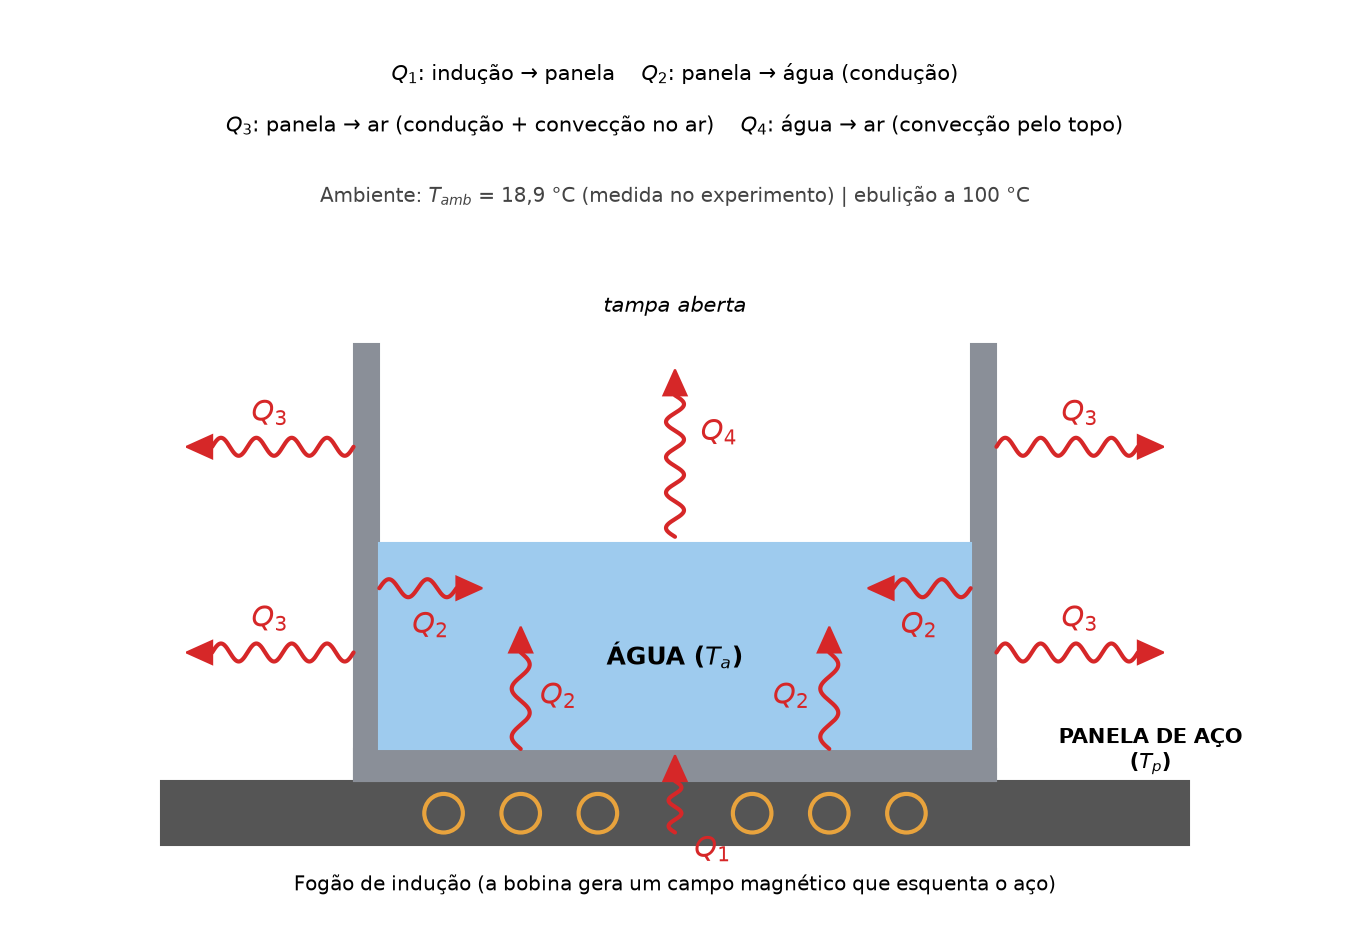
</div>

| Fluxo | De onde → para onde | Como o calor passa |
|---|---|---|
| $Q_1$ | fogão → panela | **indução**: o campo magnético esquenta o aço do fundo |
| $Q_2$ | panela → água | **condução** pela parede e pelo fundo, onde a água encosta |
| $Q_3$ | panela → ar | **condução** na parede + **convecção** no ar em volta, em toda a altura da panela |
| $Q_4$ | água → ar | **convecção** no ar acima da superfície da água (a panela está sem tampa) |

> **Para entender: condução × convecção.** **Condução** é o calor passando por dentro de um material parado (aqui, o aço da parede): é por isso que o cabo de uma colher de metal esquenta. **Convecção** é o calor sendo levado por um fluido em movimento (aqui, o ar): o ar perto da panela esquenta, sobe e é trocado por ar mais frio.

Fluxos de calor são medidos em **watts** ($W = J/s$): quantos joules de energia passam a cada segundo.

### 2.2 - Diagrama de estoques e fluxos

<div style="text-align: center;">
    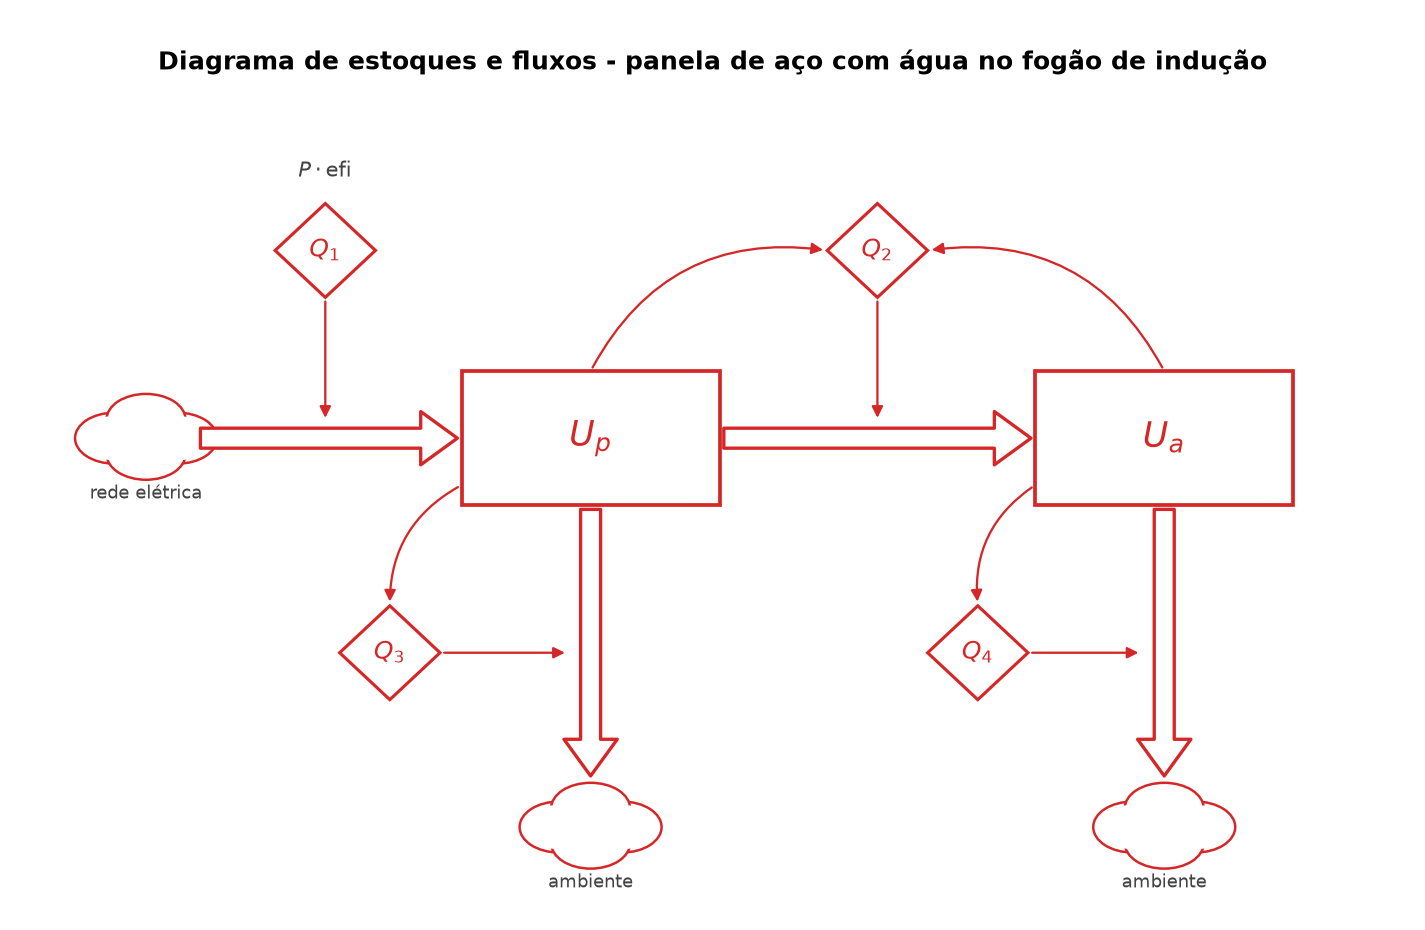
</div>

**Como ler o diagrama:**

| Símbolo | Significa | No nosso modelo |
|---|---|---|
| retângulo | **estoque**: algo que se acumula | $U_p$ (energia interna da panela) e $U_a$ (energia interna da água), em $J$ |
| seta grossa | **fluxo**: o que entra ou sai do estoque | $Q_1$, $Q_2$, $Q_3$ e $Q_4$, em $W$ |
| losango | a **fórmula** que calcula o fluxo | por exemplo, $Q_1 = P \cdot \text{efi}$ |
| seta fina | "**depende de**" | $Q_2$ depende dos dois estoques, porque depende de $T_p$ e de $T_a$ |
| nuvem | o que está **fora** do sistema | a rede elétrica (de onde vem a energia) e o ambiente (para onde ela vai) |

Lendo o diagrama: a panela **recebe** $Q_1$ e **perde** $Q_2$ e $Q_3$; a água **recebe** $Q_2$ e **perde** $Q_4$.

> **Para entender: por que 2 estoques?** Cada estoque guarda energia. Quanto ele guarda a cada grau depende da **capacidade térmica** $m \cdot c$: a panela tem $m_p \cdot c_p = 0,75 \cdot 500 = 375\ J/°C$ e a água tem $m_a \cdot c_a = 1,123 \cdot 4186 \approx 4701\ J/°C$. Ou seja, para subir $1\ °C$ a água precisa de cerca de **12 vezes** mais energia que a panela. Como nenhuma das duas é desprezível, as duas viram estoques.

### 2.3 - Equações diferenciais

Vamos montar as equações em 4 passos.

**Passo 1 - Balanço de energia (1ª Lei da Termodinâmica).** A energia de cada estoque muda de acordo com o que entra menos o que sai (não há trabalho):

$$
\left\{
    \begin{array}{l}
        \dfrac{dU_p}{dt} = Q_1 - Q_2 - Q_3 \\
        \dfrac{dU_a}{dt} = Q_2 - Q_4 \\
    \end{array}
\right.
$$

> **Para entender:** é como o saldo de uma conta bancária: quanto o saldo muda por mês é o que entra menos o que sai. Se entra mais do que sai, o saldo sobe. Aqui o "saldo" é a energia, e quando a energia sobe, a temperatura sobe junto.

**Passo 2 - Calor do fogão.** Nem toda a potência elétrica $P$ vira calor na panela: a fração que vira é a eficiência da indução, $\text{efi} = 0,85$ (ou seja, $85\%$):

$$Q_1 = P \cdot \text{efi}$$

**Passo 3 - Os outros fluxos, com resistências térmicas.** O calor flui por causa de uma **diferença de temperatura**, e cada caminho "atrapalha" a passagem com uma **resistência térmica** $R$:

$$Q = \frac{\Delta T}{R}$$

> **Para entender: é igual a um circuito elétrico.** Na Lei de Ohm, $I = \dfrac{V}{R}$. Aqui a diferença de temperatura $\Delta T$ faz o papel da tensão, o fluxo de calor $Q$ faz o papel da corrente, e $R$ continua sendo a resistência. Quanto maior a diferença de temperatura, mais calor passa; quanto maior a resistência, menos calor passa. E, como no circuito, **resistências em série se somam**.

<div style="text-align: center;">
    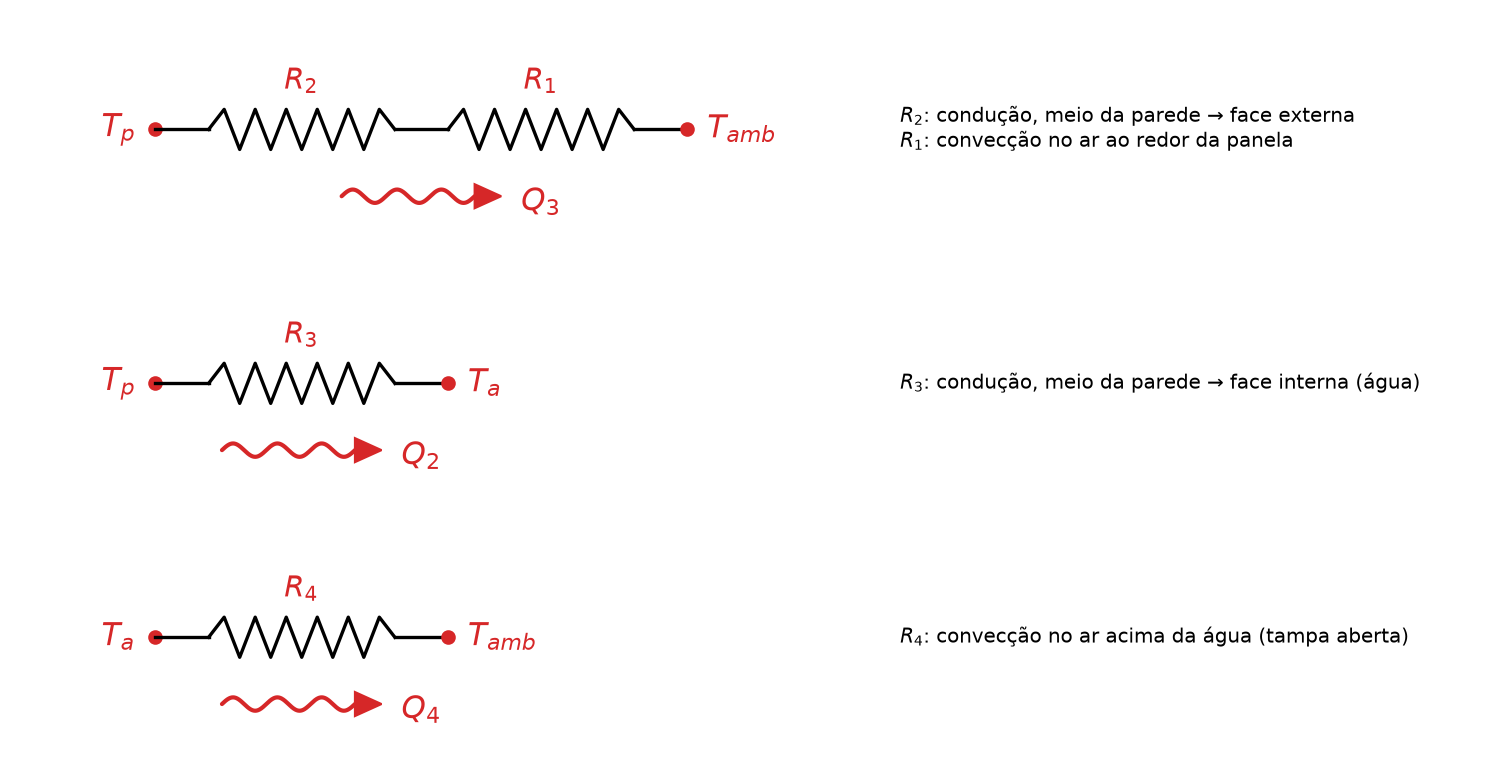
</div>

| Resistência | Tipo | Onde fica | Fórmula |
|---|---|---|---|
| $R_1$ | convecção | no ar em volta da parede da panela | $R_1 = \dfrac{1}{h_{ar} \cdot A_{lateral}}$ |
| $R_2$ | condução | do meio da parede até a face de fora | $R_2 = \dfrac{d/2}{K_{aço} \cdot A_{lateral}}$ |
| $R_3$ | condução | do meio da parede até a face de dentro (água) | $R_3 = \dfrac{d/2}{K_{aço} \cdot A_p}$ |
| $R_4$ | convecção | no ar acima da superfície da água | $R_4 = \dfrac{1}{h_{ar} \cdot A_{aberta}}$ |

- **Condução** (lei de Fourier): $R = \dfrac{L}{K \cdot A}$. Parede mais grossa ($L$ maior) ou material que conduz mal ($K$ menor) dão **mais** resistência; área maior dá **menos** resistência.
- **Convecção** (lei de Newton do resfriamento): $R = \dfrac{1}{h \cdot A}$. Quanto maior o $h$ (ar trocando calor mais facilmente) ou a área, **menos** resistência.
- **Por que $d/2$?** A temperatura $T_p$ representa o **meio** da parede. Para chegar a cada face, o calor atravessa só metade da espessura.

Com isso, os fluxos ficam:

$$Q_2 = \frac{T_p - T_a}{R_3} \qquad Q_3 = \frac{T_p - T_{amb}}{R_1 + R_2} \qquad Q_4 = \frac{T_a - T_{amb}}{R_4}$$

- Em $Q_3$, o calor atravessa **duas** resistências em série (primeiro metade da parede, $R_2$, depois o ar, $R_1$), por isso elas se somam.
- $Q_2$ só tem $R_3$, porque não colocamos resistência de convecção na água (hipótese 5).
- $Q_4$ só tem $R_4$, porque a superfície da água encosta direto no ar.

Nessas fórmulas, $T_p$ é a temperatura da panela, $T_a$ a da água e $T_{amb}$ a do ar ambiente (constante), todas em $°C$. $T_p$ e $T_a$ **não têm um valor fixo**: elas mudam com o tempo e são justamente o que o modelo calcula. O que definimos é só o valor delas no início, em $t = 0$ (seção 2.4).

**Passo 4 - De energia para temperatura.** O `odeint` vai calcular temperaturas, então trocamos $U$ por $T$. Pelo calor sensível ($Q = m \cdot c \cdot \Delta T$), temos $\dfrac{dU}{dt} = m \cdot c \cdot \dfrac{dT}{dt}$. Dividindo o balanço do passo 1 por $m \cdot c$:

$$
\left\{
    \begin{array}{l}
        \dfrac{dT_p}{dt} = \dfrac{1}{m_p \cdot c_p} \cdot \left( P \cdot \text{efi} - \dfrac{T_p - T_a}{R_3} - \dfrac{T_p - T_{amb}}{R_1 + R_2} \right) \\[4mm]
        \dfrac{dT_a}{dt} = \dfrac{1}{m_a \cdot c_a} \cdot \left( \dfrac{T_p - T_a}{R_3} - \dfrac{T_a - T_{amb}}{R_4} \right) \\
    \end{array}
\right.
$$

> **Para entender:** $\dfrac{dT}{dt}$ é a "velocidade" com que a temperatura sobe, em $°C$ por segundo. Ela é grande quando entra muito mais calor do que sai, e vai a zero quando o que entra é igual ao que sai. Esse ponto em que a temperatura para de mudar é o **equilíbrio térmico**.

**De onde vem cada fórmula** (apostila, Aulas 14 a 16):

| Fórmula | Origem |
|---|---|
| $\dfrac{dU}{dt} = \sum Q_{entra} - \sum Q_{sai}$ | 1ª Lei da Termodinâmica (sem trabalho) |
| $\dfrac{dU}{dt} = m \cdot c \cdot \dfrac{dT}{dt}$ | calor sensível, $Q = m \cdot c \cdot \Delta T$ |
| $Q_1 = P \cdot \text{efi}$ | rendimento: potência útil = potência elétrica × eficiência |
| $R_{cond} = \dfrac{L}{K \cdot A}$ | lei de Fourier (condução) |
| $R_{conv} = \dfrac{1}{h \cdot A}$ | lei de Newton do resfriamento (convecção) |

### 2.4 - Parâmetros

| Parâmetro | Símbolo | No código | Valor | Unidade | Origem |
|---|---|---|---|---|---|
| raio da panela | $r$ | `r` | 0,080 | m | **medido**: diâmetro de 160,0 mm (média de 10 medidas) |
| altura da panela | $H$ | `H` | 0,0812 | m | **medido**: 81,2 mm (média de 5 medidas) |
| espessura da parede | $d$ | `d` | 0,00054 | m | **medido**: 0,54 mm (média de 5 medidas) |
| profundidade interna | $prof$ | `prof` | 0,0775 | m | **medido**: 77,5 mm (média de 5 medidas) |
| densidade do aço inox | $\rho_{aço}$ | `rho_aco` | 7900 | kg/m³ | tabela |
| massa da panela | $m_p$ | `mp` | 0,75 | kg | **calculada** pelo volume de aço (ver abaixo) |
| calor específico do aço | $c_p$ | `cp` | 500 | J/(kg·K) | tabela |
| condutividade do aço | $K_{aço}$ | `Kaco` | 16 | W/(m·K) | tabela |
| massa de água | $m_a$ | `ma` | 1,123 | kg | **medido**: 1123 g na balança |
| calor específico da água | $c_a$ | `ca` | 4186 | J/(kg·K) | tabela |
| potência elétrica média do fogão | $P$ | `P` | 200 | W | média no experimento (ver abaixo); varia no gráfico conclusivo |
| eficiência da indução | $\text{efi}$ | `efi` | 0,85 | - | típico: 0,84 a 0,90 |
| convecção no ar | $h_{ar}$ | `har` | 60 | W/(m²·K) | **ajustado** (ver abaixo) |
| temperatura ambiente | $T_{amb}$ | `Tamb` | 18,9 | °C | **medido** no experimento |
| temperatura de ebulição | $T_{eb}$ | `Teb` | 100 | °C | nível do mar |

**Condições iniciais** (medidas no início do experimento; consideramos a água na mesma temperatura da panela):

| Variável | Símbolo | No código | Valor inicial | Unidade |
|---|---|---|---|---|
| temperatura da panela | $T_p(0)$ | `Tp0` | 20,7 | °C |
| temperatura da água | $T_a(0)$ | `Ta0` | 20,7 | °C |

> **Para entender: °C ou K?** Nas fórmulas só aparecem **diferenças** de temperatura (como $T_p - T_a$). Uma diferença de $1\ °C$ é igual a uma diferença de $1\ K$, então podemos usar °C direto, sem converter.

**Massa da panela (calculada):** a panela é um cilindro de aço. O fundo é mais grosso que a parede: a espessura do fundo é a altura de fora menos a profundidade de dentro, $e_{fundo} = H - prof \approx 3,7\ mm$. A massa é a densidade vezes o volume de aço (parede lateral + fundo):

$$m_p = \rho_{aço} \cdot \left( 2 \pi r \cdot prof \cdot d + \pi r^2 \cdot e_{fundo} \right) \approx 0,75\ kg$$

Não consideramos o cabo da panela. A conta é refeita no código, logo abaixo, para conferir.

**Áreas** (cada resistência usa a área por onde o calor passa):
- $A_{aberta} = \pi r^2$ (`Apanelaaberta`): a boca da panela, que é a superfície da água em contato com o ar.
- $h_{agua} = \dfrac{m_a / 1000}{\pi r^2}$ (`h_agua`): altura da água. É o volume de água ($m_a$ dividido pela densidade, $1000\ kg/m^3$) dividido pela área do fundo.
- $A_p = \pi r^2 + 2 \pi r \cdot h_{agua}$ (`Ap`): parte da panela que encosta na água (fundo + lateral até a altura da água).
- $A_{lateral} = 2 \pi r H$ (`Aplateral`): lateral inteira da panela, que perde calor para o ar.

**Por que $P = 200\ W$:** no experimento, o fogão ficou no modo $150\ °C$. Nesse modo ele **liga e desliga** sozinho para controlar a temperatura (como um ferro de passar roupa). Medimos a tensão da tomada ($220\ V$, valor eficaz) e a corrente máxima com o fogão ligado ($3,2\ A$). Com o fogão ligado, a potência é $P_{ligado} = V_{ef} \cdot \dfrac{I_{máx}}{\sqrt{2}} \approx 498\ W$ (calculada no código). Como ele não fica ligado o tempo todo, o que importa para o modelo é a potência **média**. A média que reproduz os dados é $P \approx 200\ W$, ou seja, o fogão ficou ligado cerca de $40\%$ do tempo.

**Por que $h_{ar} = 60$:** com $200\ W$ a água **não ferveu**: ela estabilizou perto de $66\ °C$, porque o calor que entrava passou a ser igual ao calor perdido para o ambiente (equilíbrio térmico). O $h_{ar}$ controla o tamanho dessas perdas: com $h_{ar}$ maior a panela perde mais calor e a água estabiliza mais baixo; com $h_{ar}$ menor, mais alto. Com $h_{ar} = 10$ (convecção natural), o modelo perdia pouco calor e a água fervia. Testamos valores maiores, e $h_{ar} = 60$ fez o modelo estabilizar na mesma temperatura do experimento. Ele fica acima da faixa da convecção natural ($2$ a $25$) porque, no modelo, também representa as perdas que não modelamos separadamente: **evaporação** (a panela está sem tampa) e **radiação**.

Usamos a potência **elétrica** $P$, e não a útil, porque é o valor que se escolhe no fogão e que se conhece no experimento.

Fontes dos valores de tabela: engineeringtoolbox.com e Incropera, *Fundamentos de Transferência de Calor e de Massa*.

In [2]:
# ---------------- Panela ----------------
r = 0.080         # raio [m] (medido: diâmetro 160,0 mm)
H = 0.0812        # altura [m] (medido: 81,2 mm)
d = 0.00054       # espessura da parede [m] (medido: 0,54 mm)
prof = 0.0775     # profundidade interna [m] (medida: 77,5 mm)
rho_aco = 7900    # densidade do aço inox [kg/m3] (tabela)
mp = 0.75         # massa da panela [kg] (calculada pelo volume de aço, ver 2.4)
cp = 500          # calor específico do aço [J/(kg.K)]
Kaco = 16         # condutividade térmica do aço [W/(m.K)]

# ---------------- Água ----------------
ma = 1.123        # massa [kg] (medida: 1123 g)
ca = 4186         # calor específico [J/(kg.K)]

# ---------------- Fogão e ambiente ----------------
V_ef = 220                              # tensão eficaz da tomada [V]
I_max = 3.2                             # corrente máxima medida com o fogão ligado [A]
P_ligado = V_ef * I_max / np.sqrt(2)    # potência com o fogão ligado [W] (~498 W)
P = 200           # potência elétrica MÉDIA [W] (o fogão liga e desliga no modo 150 °C)
efi = 0.85        # eficiência da indução [-]
har = 60          # coef. de convecção do ar [W/(m2.K)] (ajustado, ver 2.4)
Tamb = 18.9       # temperatura ambiente [°C] (medida)
Teb = 100         # temperatura de ebulição [°C]

# ---------------- Condições iniciais ----------------
Tp0 = 20.7        # temperatura inicial da panela [°C] (medida)
Ta0 = 20.7        # temperatura inicial da água [°C] (igual à da panela)

# ---------------- Áreas [m2] ----------------
Apanelaaberta = np.pi * r**2                    # boca da panela = superfície da água
h_agua = (ma / 1000) / Apanelaaberta            # altura da água [m] (volume / área)
Ap = Apanelaaberta + 2 * np.pi * r * h_agua     # panela em contato com a água (fundo + lateral molhada)
Aplateral = 2 * np.pi * r * H                   # lateral inteira da panela

# ---------------- Resistências térmicas [K/W] ----------------
R1 = 1 / (har * Aplateral)              # convecção: ar ao redor da panela
R2 = (d / 2) / (Kaco * Aplateral)       # condução: meio da parede -> face externa
R3 = (d / 2) / (Kaco * Ap)              # condução: meio da parede -> face interna (água)
R4 = 1 / (har * Apanelaaberta)          # convecção: ar acima da superfície da água

### 2.5 - Conferindo os valores calculados

Antes de simular, vale olhar os números que o código calculou. Isso ajuda a entender o modelo e a achar erros de digitação.

In [3]:
e_fundo = H - prof                                                  # espessura do fundo [m]
mp_calculada = rho_aco * (2*np.pi*r*prof*d + np.pi*r**2*e_fundo)    # massa da panela pelo volume de aço [kg]

print(f"Massa da panela calculada: {mp_calculada:.3f} kg (no modelo usamos mp = {mp} kg)")
print(f"Potência com o fogão ligado: {P_ligado:.0f} W -> com P = {P} W ele fica ligado {P / P_ligado * 100:.0f} % do tempo")
print(f"Altura da água: {h_agua * 100:.1f} cm")
print(f"Capacidade térmica da panela: {mp * cp:.0f} J/°C | da água: {ma * ca:.0f} J/°C")
print()
print(f"R1 = {R1:.4f} K/W     (convecção, ar em volta da panela)")
print(f"R2 = {R2:.6f} K/W   (condução, metade da parede, lado de fora)")
print(f"R3 = {R3:.6f} K/W   (condução, metade da parede, lado da água)")
print(f"R4 = {R4:.4f} K/W     (convecção, ar acima da água)")

Massa da panela calculada: 0.754 kg (no modelo usamos mp = 0.75 kg)
Potência com o fogão ligado: 498 W -> com P = 200 W ele fica ligado 40 % do tempo
Altura da água: 5.6 cm
Capacidade térmica da panela: 375 J/°C | da água: 4701 J/°C

R1 = 0.4083 K/W     (convecção, ar em volta da panela)
R2 = 0.000413 K/W   (condução, metade da parede, lado de fora)
R3 = 0.000350 K/W   (condução, metade da parede, lado da água)
R4 = 0.8289 K/W     (convecção, ar acima da água)


**O que esses números mostram:** as resistências de condução ($R_2$ e $R_3$) são cerca de **mil vezes menores** que as de convecção ($R_1$ e $R_4$). O aço conduz bem e a parede é finíssima, então quase toda a "dificuldade" para o calor sair está no **ar**. Duas consequências:
1. $T_p$ fica praticamente igual a $T_a$ (ver 3.2).
2. O parâmetro que mais controla as perdas de calor é o $h_{ar}$, e por isso foi ele que ajustamos.

---
## 3. Implementação

### 3.1 - Função do modelo

A função `modelo` traduz as equações do passo 4 (seção 2.3) para Python. O `odeint` vai chamar essa função muitas vezes.

Ela recebe:
- `x`: uma **lista** com as temperaturas naquele instante, `[Tp, Ta]`
- `t`: o instante de tempo [s] (o `odeint` exige esse argumento, mesmo que a função não use)

E devolve:
- uma **lista** com as derivadas `[dTpdt, dTadt]`: quanto cada temperatura está subindo por segundo naquele instante.

A ordem importa: como `x` vem como `[Tp, Ta]`, as derivadas têm que voltar na mesma ordem, `[dTpdt, dTadt]`.

In [4]:
def modelo(x, t):
    Tp = x[0]    # temperatura da panela [°C]
    Ta = x[1]    # temperatura da água [°C]

    # Fluxos de calor [W]
    Q1 = P * efi                     # fogão -> panela
    Q2 = (Tp - Ta) / R3              # panela -> água
    Q3 = (Tp - Tamb) / (R1 + R2)     # panela -> ar
    Q4 = (Ta - Tamb) / R4            # água -> ar

    # Taxas de variação das temperaturas [°C/s]
    dTpdt = (Q1 - Q2 - Q3) / (mp * cp)    # panela: recebe Q1, perde Q2 e Q3
    dTadt = (Q2 - Q4) / (ma * ca)         # água: recebe Q2, perde Q4

    dxdt = [dTpdt, dTadt]
    return dxdt

### 3.2 - Gráfico das temperaturas

> **Para entender: o que o `odeint` faz?** Ele começa nas condições iniciais `x0` e anda no tempo em passos pequenos. Em cada passo, chama a função `modelo` para saber a "velocidade" de cada temperatura e calcula o valor seguinte, mais ou menos assim: $T(t + \Delta t) \approx T(t) + \dfrac{dT}{dt} \cdot \Delta t$ (é a ideia do método de Euler; o `odeint` faz isso de um jeito mais preciso). No fim, ele devolve uma tabela com **uma linha por instante** da lista de tempo e **uma coluna por estoque**: coluna 0 = $T_p$, coluna 1 = $T_a$.

O que a célula abaixo faz:
1. Resolve as equações para a potência do experimento ($P = 200\ W$), de $0$ a $7200\ s$ (2 horas), com passo de $1\ s$, partindo de $T_p(0) = T_a(0) = 20,7\ °C$.
2. Com um `while`, procura o primeiro instante em que a água chega a $100\ °C$.
3. Plota as temperaturas. Como desprezamos a evaporação, o modelo só vale **até a água ferver**: se ela ferver, o gráfico para nesse instante. Se não ferver (como com $200\ W$), o gráfico mostra as 2 horas.

**O que esperar do gráfico:** no começo a temperatura sobe rápido, porque a água está fria e quase não perde calor. Conforme ela esquenta, as perdas para o ar ($Q_3$ e $Q_4$) aumentam, a subida fica mais lenta e a curva "achata". Ela se aproxima do **equilíbrio térmico**, a temperatura em que o calor que entra ($Q_1$) é igual ao que sai ($Q_3 + Q_4$). Com $200\ W$ isso acontece antes dos $100\ °C$, então a água não ferve.

**Por que as duas curvas ficam uma em cima da outra?** A diferença entre $T_p$ e $T_a$ é menor que $0,1\ °C$, porque $R_3$ é muito pequena (seção 2.5): o calor passa da panela para a água quase sem precisar de diferença de temperatura. Por isso a curva da panela está tracejada, para aparecer por cima da curva da água.

Com P = 200 W, a água não ferve: depois de 120 min ela está a 65.2 °C (equilíbrio térmico)


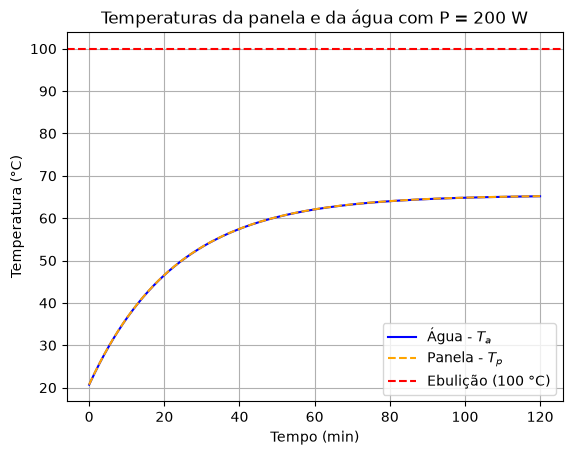

In [5]:
# Condições iniciais [Tp(0), Ta(0)] e lista de tempo
x0 = [Tp0, Ta0]
dt = 1                               # passo de tempo [s]
t_lista = np.arange(0, 7200, dt)     # tempo [s] (2 horas)

# Resolve as equações: coluna 0 = Tp, coluna 1 = Ta
x = odeint(modelo, x0, t_lista)
Tp_lista = x[:, 0]
Ta_lista = x[:, 1]

# Procura o instante em que a água ferve (ou para no fim da lista de tempo)
i = 0
while i < len(t_lista) - 1 and Ta_lista[i] < Teb:
    i = i + 1

if Ta_lista[i] >= Teb:
    print(f"Com P = {P} W, a água ferve em {t_lista[i]} s = {t_lista[i]/60:.1f} min")
else:
    print(f"Com P = {P} W, a água não ferve: depois de {t_lista[-1]/60:.0f} min ela está a {Ta_lista[-1]:.1f} °C (equilíbrio térmico)")

# Plota até a água ferver ou até o fim da lista de tempo (tempo em minutos)
plt.plot(t_lista[:i+1] / 60, Ta_lista[:i+1], 'b', label='Água - $T_a$')
plt.plot(t_lista[:i+1] / 60, Tp_lista[:i+1], '--', color='orange', label='Panela - $T_p$')   # tracejada para aparecer por cima da água
plt.axhline(Teb, color='r', linestyle='--', label='Ebulição (100 °C)')

# Configura gráfico
plt.xlabel('Tempo (min)')
plt.ylabel('Temperatura (°C)')
plt.title(f'Temperaturas da panela e da água com P = {P} W')
plt.legend()
plt.grid(True)
plt.show()

### 3.3 - Comportamento em 60 minutos

Mesmo resultado do item 3.2 (mesma potência $P$), mas com o eixo do tempo indo só até $60\ min$, para ver melhor a subida inicial. Se a água ferver, as curvas terminam quando ela chega a $100\ °C$, porque depois disso o modelo não vale mais (desprezamos a evaporação).

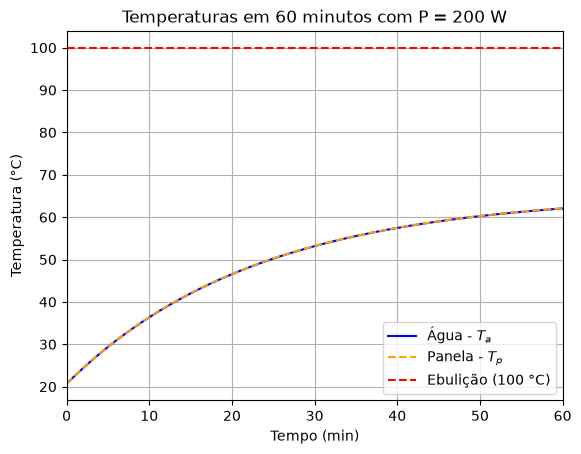

In [6]:
# Usa as listas do item 3.2: as curvas vão só até a água ferver (índice i)
plt.plot(t_lista[:i+1] / 60, Ta_lista[:i+1], 'b', label='Água - $T_a$')
plt.plot(t_lista[:i+1] / 60, Tp_lista[:i+1], '--', color='orange', label='Panela - $T_p$')   # tracejada para aparecer por cima da água
plt.axhline(Teb, color='r', linestyle='--', label='Ebulição (100 °C)')

# Configura gráfico: eixo do tempo de 0 a 60 min
plt.xlim(0, 60)
plt.xlabel('Tempo (min)')
plt.ylabel('Temperatura (°C)')
plt.title(f'Temperaturas em 60 minutos com P = {P} W')
plt.legend()
plt.grid(True)
plt.show()

### 3.4 - Conferindo o equilíbrio "à mão"

No equilíbrio as temperaturas param de mudar ($\dfrac{dT}{dt} = 0$), então tudo o que entra sai: $Q_1 = Q_3 + Q_4$. Como $T_p \approx T_a$, chamamos as duas de $T_{eq}$:

$$P \cdot \text{efi} = \frac{T_{eq} - T_{amb}}{R_1 + R_2} + \frac{T_{eq} - T_{amb}}{R_4} \quad \Rightarrow \quad T_{eq} = T_{amb} + \frac{P \cdot \text{efi}}{\dfrac{1}{R_1 + R_2} + \dfrac{1}{R_4}}$$

Se essa conta der perto do valor final do gráfico, o código está coerente com as equações.

In [7]:
T_eq = Tamb + P * efi / (1 / (R1 + R2) + 1 / R4)    # temperatura de equilíbrio [°C]

print(f"Equilíbrio calculado à mão: {T_eq:.1f} °C")
print(f"Água no fim da simulação (2 h): {Ta_lista[-1]:.1f} °C")

Equilíbrio calculado à mão: 65.4 °C
Água no fim da simulação (2 h): 65.2 °C


---
## 4. Validação

Validar é comparar o modelo com um **experimento real**, para saber se ele representa a realidade.

**Experimento:**
1. Medimos a panela (diâmetro, altura e espessura) e colocamos os valores na seção 2.4.
2. Colocamos $1123\ g$ de água, sem tampa, e anotamos as temperaturas iniciais: ambiente $18,9\ °C$ e panela $20,7\ °C$.
3. Ligamos o fogão no modo $150\ °C$. Nesse modo ele liga e desliga; a potência média ficou em cerca de $200\ W$ (ver seção 2.4).
4. Anotamos a temperatura da água **a cada 3 minutos, de 3 a 96 minutos**.

**Correção do tempo:** percebemos que o cronômetro começou cerca de **7 minutos antes** de o fogão começar a aquecer a água: nos primeiros minutos a água quase não esquentou ($21,1\ °C$ aos 3 min e $21,9\ °C$ aos 6 min). Por isso, descontamos 7 min de todos os tempos medidos: o ponto anotado aos 9 min corresponde a 2 min de aquecimento, o de 12 min a 5 min, e assim por diante. Os pontos de 3 e 6 min ficam antes do início do aquecimento e não entram na validação.

**Como calculamos o erro:** para cada ponto medido $i$, comparamos a temperatura do modelo com a medida:

$$\text{erro}_i = \frac{\left| T_{modelo,i} - T_{exp,i} \right|}{T_{exp,i}} \cdot 100\%$$

e o **erro percentual médio** é a média desses erros. O modelo é calculado a cada $1\ s$, mas medimos de 3 em 3 minutos; o `np.interp` pega o valor do modelo exatamente nos instantes medidos, para comparar um com o outro.

Na validação, a simulação vai de $0$ até o último instante medido. Depois que a água ferve, o modelo fica parado em $T_{eb}$, porque a água não passa da temperatura de ebulição (com $200\ W$ isso não acontece).

Tempo total do experimento: 5340 s = 89.0 min
Erro percentual médio: 2.78 %
Maior erro: 6.8 % (aos 11 min de aquecimento)


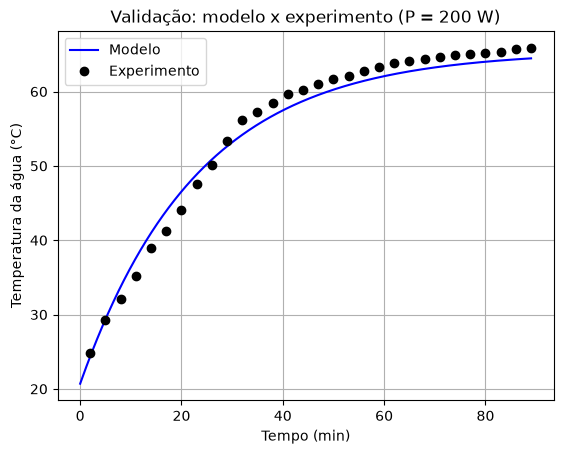

In [8]:
# ---------------- DADOS DO EXPERIMENTO ----------------
# Temperatura da água medida a cada 3 min, de 3 a 96 min (P = 200 W)
t_medido_min = np.arange(3, 96 + 3, 3)   # instantes anotados no cronômetro [min]
T_medido = [21.1, 21.9, 24.8, 29.3, 32.1, 35.2, 39.0, 41.2,
            44.0, 47.5, 50.1, 53.3, 56.2, 57.2, 58.4, 59.7,
            60.2, 61.0, 61.7, 62.1, 62.8, 63.3, 63.9, 64.1,
            64.4, 64.6, 64.9, 65.0, 65.2, 65.3, 65.7, 65.9]   # temperaturas da água [°C]

# Correção: o cronômetro começou 7 min antes de o fogão aquecer a água
atraso_min = 7                           # [min]

t_exp_lista = []                         # tempo desde o início do aquecimento [s]
T_exp_lista = []                         # temperaturas da água [°C]
for j in range(len(t_medido_min)):
    t_corrigido = t_medido_min[j] - atraso_min        # [min]
    if t_corrigido >= 0:                              # descarta pontos antes do aquecimento
        t_exp_lista.append(t_corrigido * 60)          # [s]
        T_exp_lista.append(T_medido[j])
# -------------------------------------------------------

# Tempo total = tempo que o experimento levou (último instante medido)
t_total = max(t_exp_lista)               # [s]

# Simula do início do aquecimento até o último ponto medido
x0 = [Tp0, Ta0]
t_lista_val = np.arange(0, t_total + dt, dt)

x = odeint(modelo, x0, t_lista_val)
Ta_val = np.minimum(x[:, 1], Teb)        # depois de ferver, a água fica em Teb

t_exp = np.array(t_exp_lista)
T_exp = np.array(T_exp_lista)

# Temperatura do modelo nos mesmos instantes em que medimos
T_modelo = np.interp(t_exp, t_lista_val, Ta_val)

# Erro percentual de cada ponto e a média deles
erros = np.abs(T_modelo - T_exp) / T_exp * 100
erro_medio = np.mean(erros)
print(f"Tempo total do experimento: {t_total} s = {t_total/60:.1f} min")
print(f"Erro percentual médio: {erro_medio:.2f} %")
print(f"Maior erro: {np.max(erros):.1f} % (aos {t_exp[np.argmax(erros)]/60:.0f} min de aquecimento)")

# Plota o modelo (linha) e o experimento (pontos) no mesmo gráfico
plt.plot(t_lista_val / 60, Ta_val, 'b', label='Modelo')
plt.plot(t_exp / 60, T_exp, 'ko', label='Experimento')

# Configura gráfico
plt.xlabel('Tempo (min)')
plt.ylabel('Temperatura da água (°C)')
plt.title(f'Validação: modelo x experimento (P = {P} W)')
plt.legend()
plt.grid(True)
plt.show()

**O que a validação mostra:**
- O erro médio ficou abaixo de $3\%$: o modelo representa bem o experimento, tanto a subida da temperatura quanto o equilíbrio perto de $65\ °C$.
- Entre cerca de 5 e 27 min o modelo fica um pouco **acima** dos pontos (esquenta um pouco mais rápido que a água real) e, depois de uns 30 min, fica um pouco **abaixo**.
- Possíveis motivos para essas diferenças: a potência real não é constante (o fogão liga e desliga, e usamos a média); o instante exato em que o aquecimento começou é aproximado (a correção de 7 min); o $h_{ar}$ é constante no modelo, mas na realidade as perdas, principalmente a evaporação, mudam com a temperatura; e o termômetro mede a água em um ponto só.

---
## 5. Gráfico conclusivo

Agora respondemos à pergunta: *quanto tempo a água demora para ferver em função da potência do fogão?*

1. Criamos a função `modelo2`. Ela é igual à `modelo`, mas recebe a potência $P$ como **argumento a mais**, para podermos trocar a potência a cada simulação (o `args=(P_atual,)` do `odeint` passa esse valor para a função).
2. Rodamos o `odeint` em um **loop**, uma vez para cada potência de $100\ W$ a $3500\ W$ (de $50$ em $50\ W$), mantendo todos os outros parâmetros iguais.
3. Em cada simulação, o `while` procura o instante em que a água chega a $T_{eb}$ e guardamos esse tempo.
4. Se a água não ferver dentro da lista de tempo (2 horas), guardamos `np.nan` ("not a number"), e esse ponto não aparece no gráfico.

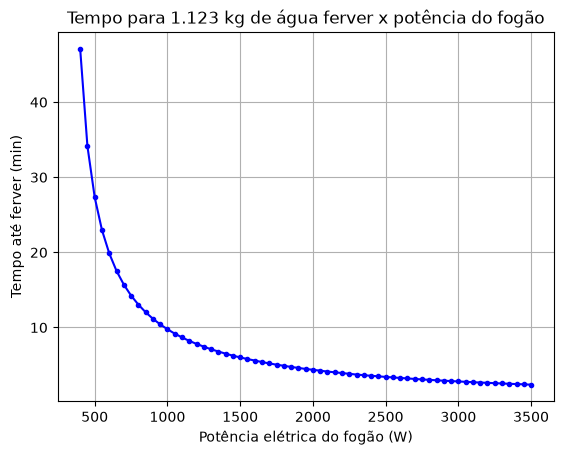

P = 400 W -> ferve em 47.1 min
P = 1000 W -> ferve em 9.8 min
P = 2000 W -> ferve em 4.4 min
P = 3500 W -> ferve em 2.4 min


In [9]:
# Igual à função modelo, mas recebe a potência P [W] como argumento
def modelo2(x, t, P):
    Tp = x[0]    # temperatura da panela [°C]
    Ta = x[1]    # temperatura da água [°C]

    # Fluxos de calor [W]
    Q1 = P * efi                     # fogão -> panela
    Q2 = (Tp - Ta) / R3              # panela -> água
    Q3 = (Tp - Tamb) / (R1 + R2)     # panela -> ar
    Q4 = (Ta - Tamb) / R4            # água -> ar

    # Taxas de variação das temperaturas [°C/s]
    dTpdt = (Q1 - Q2 - Q3) / (mp * cp)
    dTadt = (Q2 - Q4) / (ma * ca)

    dxdt = [dTpdt, dTadt]
    return dxdt


P_lista = np.arange(100, 3500 + 50, 50)    # potências testadas [W]
t_eb_lista = []                            # tempo até ferver [s]

x0 = [Tp0, Ta0]
for P_atual in P_lista:
    x = odeint(modelo2, x0, t_lista, args=(P_atual,))
    Ta_lista_P = x[:, 1]

    i = 0
    while i < len(t_lista) - 1 and Ta_lista_P[i] < Teb:
        i = i + 1

    if Ta_lista_P[i] >= Teb:
        t_eb_lista.append(t_lista[i])
    else:
        t_eb_lista.append(np.nan)          # não ferveu em 2 horas

t_eb_lista = np.array(t_eb_lista)

plt.plot(P_lista, t_eb_lista / 60, 'b.-')

# Configura gráfico
plt.xlabel('Potência elétrica do fogão (W)')
plt.ylabel('Tempo até ferver (min)')
plt.title(f'Tempo para {ma} kg de água ferver x potência do fogão')
plt.grid(True)
plt.show()

# Alguns valores do gráfico
for P_ver in [400, 1000, 2000, 3500]:
    k = list(P_lista).index(P_ver)
    print(f"P = {P_ver} W -> ferve em {t_eb_lista[k]/60:.1f} min")

### 5.1 - Como ler o gráfico

- **Mais potência, menos tempo**, mas a curva vai "deitando": de $1000\ W$ para $2000\ W$ o tempo cai uns 5 minutos, enquanto de $2000\ W$ para $3500\ W$ cai só uns 2 minutos.
- **Existe uma potência mínima.** Abaixo dela a água chega ao equilíbrio antes dos $100\ °C$ e **nunca** ferve (foi o que aconteceu no experimento com $200\ W$). Por isso o gráfico não tem pontos nas potências mais baixas.

As duas contas abaixo explicam esses comportamentos "à mão":

1. **Sem perdas**, toda a potência útil iria para esquentar a panela e a água de $20,7\ °C$ a $100\ °C$:
$$t_{sem\ perdas} = \frac{(m_a \cdot c_a + m_p \cdot c_p) \cdot (T_{eb} - T_0)}{P \cdot \text{efi}}$$
Esse tempo é proporcional a $\dfrac{1}{P}$: dobrar a potência corta o tempo pela metade, e por isso a curva vai deitando.

2. **Potência mínima:** é a potência em que o equilíbrio fica exatamente em $100\ °C$ (mesma conta da seção 3.4, com $T_{eq} = T_{eb}$):
$$P_{min} = \frac{1}{\text{efi}} \cdot \left( \frac{T_{eb} - T_{amb}}{R_1 + R_2} + \frac{T_{eb} - T_{amb}}{R_4} \right)$$

In [10]:
# 1. Tempo se não houvesse perdas
E_necessaria = (ma * ca + mp * cp) * (Teb - Ta0)     # energia para levar panela e água de 20,7 °C a 100 °C [J]
print(f"Energia para chegar a 100 °C: {E_necessaria / 1000:.0f} kJ")
for P_ver in [1000, 2000, 3500]:
    t_sem_perdas = E_necessaria / (P_ver * efi)       # [s]
    print(f"P = {P_ver} W -> sem perdas levaria {t_sem_perdas / 60:.1f} min")

# 2. Potência mínima para a água ferver
P_min = ((Teb - Tamb) / (R1 + R2) + (Teb - Tamb) / R4) / efi
print(f"Potência mínima para ferver: {P_min:.0f} W")

Energia para chegar a 100 °C: 403 kJ
P = 1000 W -> sem perdas levaria 7.9 min
P = 2000 W -> sem perdas levaria 3.9 min
P = 3500 W -> sem perdas levaria 2.3 min
Potência mínima para ferver: 349 W


**Comparando com o gráfico:**
- Com perdas o tempo é sempre **maior** que sem perdas, porque parte do calor vai para o ar enquanto a água esquenta. A diferença diminui com potência alta: a água chega rápido a $100\ °C$ e sobra pouco tempo para perder calor.
- A potência mínima dá cerca de $350\ W$. Logo acima dela a água até ferve, mas demora muito, porque chega perto do equilíbrio e sobe cada vez mais devagar. Por isso, dentro de 2 horas, o primeiro ponto do gráfico é $400\ W$ (47 min).

---
## 6. Resumo para a apresentação

**Números principais**

| O quê | Valor |
|---|---|
| Erro percentual médio da validação | $2,8\%$ |
| Equilíbrio da água com $200\ W$ | $\approx 65\ °C$ (não ferve) |
| Potência mínima para ferver | $\approx 350\ W$ (em até 2 h: $400\ W$, 47 min) |
| Tempo até ferver com $1000\ W$ | $9,8\ min$ |
| Tempo até ferver com $2000\ W$ | $4,4\ min$ |

**Roteiro da fala** (na ordem dos slides):
1. **Pergunta:** quanto tempo $1,1\ kg$ de água leva para ferver em função da potência do fogão.
2. **Esquema físico:** o fogão esquenta a panela ($Q_1$), a panela esquenta a água ($Q_2$) e as duas perdem calor para o ar ($Q_3$ e $Q_4$).
3. **Equações:** cada fluxo é $\Delta T / R$, como num circuito elétrico; condução na parede ($R_2$, $R_3$) e convecção no ar ($R_1$, $R_4$).
4. **Modelo:** dois estoques de energia (panela e água) e as hipóteses.
5. **Parâmetros:** o que foi medido, o que foi calculado ($m_p$) e o que foi ajustado ($P$ e $h_{ar}$), e por quê.
6. **Validação:** modelo × experimento, erro de $2,8\%$.
7. **Resultado:** tempo até ferver × potência.
8. **Conclusões:** potência mínima de $\approx 400\ W$ (para ferver em até 2 h) e, a partir de $2000\ W$, mais potência quase não reduz o tempo.

**Perguntas que podem aparecer**

- ***Por que $h_{ar} = 60$, se a convecção natural do ar fica entre 2 e 25?*** Porque no modelo ele também representa a evaporação e a radiação, que não modelamos separadamente. Ajustamos para o equilíbrio bater com o medido (cerca de $66\ °C$).
- ***Por que $200\ W$, se o fogão ligado puxa uns $500\ W$?*** No modo $150\ °C$ ele liga e desliga. $200\ W$ é a média, como se ficasse ligado $40\%$ do tempo.
- ***Por que as curvas da panela e da água ficam juntas?*** Porque a resistência de condução da parede ($R_3$) é minúscula: o calor passa do aço para a água quase sem diferença de temperatura.
- ***Por que vocês descontaram 7 minutos?*** O cronômetro começou antes do aquecimento: nos primeiros 6 minutos a água praticamente não esquentou ($21,1$ e $21,9\ °C$).
- ***Por que a água não ferveu no experimento?*** Com $200\ W$, as perdas para o ar ficaram iguais ao calor que entrava quando a água chegou a uns $65\ °C$ (equilíbrio térmico).
- ***Por que mais potência quase não reduz o tempo depois de $2000\ W$?*** Porque o tempo é praticamente a energia necessária dividida pela potência (seção 5.1), uma curva do tipo $1/P$.
- ***O que o modelo não considera?*** Evaporação e radiação como termos separados, convecção dentro da água, diferenças de temperatura dentro da água, o cabo da panela e a própria ebulição (o modelo para em $100\ °C$). Se perguntarem: em São Paulo (cerca de 760 m de altitude) a água ferve um pouco abaixo de $100\ °C$; usamos $100\ °C$ como simplificação.